# Evaluasi Verifikasi Realisasi Indikator RPJMN 2025-2029
gemma-4-26B-A4B-it vs watsonx-qwen3-30b-a3b-instruct-2507

**Pertanyaan penelitian:** Bagaimana performa dua model LLM, yaitu Gemma 4 26B A4B IT dan Qwen3-30B-A3B-Instruct-2507, dalam memverifikasi status realisasi indikator RPJMN 2025-2029 menggunakan mekanisme *tool calling* pencarian web, dibandingkan dengan *ground truth* yang telah dibangun?

Notebook ini membaca hasil notebook 4 (Qwen) dan 4b (Gemma), lalu menilai performa dari empat sisi:

| Sisi | Yang dilihat | Bagian |
| --- | --- | --- |
| Ketepatan label | Kesesuaian `pred` dengan gold, per kelas | 3-5 |
| Proses pencarian | Bagaimana model memakai *tool* pencarian web | 6 |
| Kualitas bukti | Jenis, tahun, dan keaslian sumber yang dikutip | 7-8 |
| Biaya | Token dan waktu per indikator | 9 |
| Isi summary | Apakah summary didukung sumbernya sendiri dan relevan dengan indikator | 11 |

Bagian 10 memilah baris yang salah ke dalam taksonomi kesalahan, dan bagian 12 merangkum jawaban atas pertanyaan penelitian.

Tidak ada uji hipotesis di notebook ini. Interval kepercayaan Wilson 95% hanya ditampilkan untuk memperlihatkan seberapa lebar ketidakpastian angka yang dihitung dari sedikit baris (terutama kelas FALSE yang hanya 6 baris). Label gold dipakai apa adanya, termasuk baris no=11 yang ditandai `gold_suspect`.

## 1. Setup

In [1]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

DATA_RAW = Path("../data/raw")
DATA_OUT = Path("../data/output")

# Nama pendek untuk tabel dan grafik
MODELS = {
    "gemma-4-26b-a4b-it":               "Gemma 4 26B A4B",
    "watsonx-qwen3-30b-a3b-instruct-2": "Qwen3 30B A3B",
}
ORDER  = list(MODELS.values())
COLORS = {"Gemma 4 26B A4B": "#2a78b5", "Qwen3 30B A3B": "#d9822b"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True, "font.size": 10,
})


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (c - h, c + h)


def fmt_ci(k, n):
    lo, hi = wilson(k, n)
    return f"{k/n:.1%} [{lo:.1%}-{hi:.1%}]" if n else "-"

## 2. Data

Hasil yang dipakai adalah file `detail_*` terbaru untuk tiap model, plus JSONL mentahnya (berisi `tool_calls_log`) untuk analisis proses pencarian dan kesalahan.

In [2]:
def latest(pattern):
    files = sorted(DATA_OUT.glob(pattern))
    if not files:
        raise FileNotFoundError(pattern)
    return files[-1]


frames, raws = [], []
for slug, nama in MODELS.items():
    f_det = latest(f"detail_{slug}_serper_*.csv")
    f_raw = DATA_OUT / f"raw_{slug}_serper.jsonl"
    d = pd.read_csv(f_det, encoding="utf-8-sig")
    d["model_nama"] = nama
    frames.append(d)

    with open(f_raw, encoding="utf-8") as fh:
        for line in fh:
            r = json.loads(line)
            raws.append({"model_nama": nama, "row_no": r["row_no"],
                         "tool_calls_log": r.get("tool_calls_log") or []})
    print(f"{nama:<16}: {f_det.name}  ({len(d)} baris)")

df = pd.concat(frames, ignore_index=True)
raw = pd.DataFrame(raws)

raw["n_hasil"] = raw["tool_calls_log"].apply(lambda L: sum(len(t.get("hasil") or []) for t in L))
df = df.merge(raw[["model_nama", "row_no", "n_hasil"]], on=["model_nama", "row_no"], how="left")

for c in ["gold", "pred", "benar", "domain_goid", "url_dari_search", "gold_suspect"]:
    df[c] = df[c].astype(bool)

wide = df.pivot(index="row_no", columns="model_nama", values=["pred", "benar"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.join(df.drop_duplicates("row_no").set_index("row_no")[["gold", "sektor", "kl", "sub_indikator"]])

cek = df.groupby("row_no")["gold"].nunique()
assert (cek == 1).all(), "Gold berbeda antar file model"
assert df.groupby("model_nama")["row_no"].nunique().eq(292).all(), "Jumlah baris tidak 292"
print("\nStatus run :", df.groupby("model_nama")["status"].value_counts().to_dict())

Gemma 4 26B A4B : detail_gemma-4-26b-a4b-it_serper_20260918_113127.csv  (292 baris)
Qwen3 30B A3B   : detail_watsonx-qwen3-30b-a3b-instruct-2_serper_20260917_150324.csv  (292 baris)

Status run : {('Gemma 4 26B A4B', 'OK'): 292, ('Qwen3 30B A3B', 'OK'): 292}


In [3]:
g = wide["gold"]
n_true, n_false = int(g.sum()), int((~g).sum())
print(f"Jumlah indikator : {len(g)}")
print(f"Gold TRUE        : {n_true} ({n_true/len(g):.1%})")
print(f"Gold FALSE       : {n_false} ({n_false/len(g):.1%})")
print(f"\nBaseline 'selalu TRUE' sudah mencapai akurasi {n_true/len(g):.1%}.")

Jumlah indikator : 292
Gold TRUE        : 286 (97.9%)
Gold FALSE       : 6 (2.1%)

Baseline 'selalu TRUE' sudah mencapai akurasi 97.9%.


## 3. Kinerja klasifikasi terhadap ground truth

Kelas positif adalah **TRUE** (program berjalan pada 2025). Metrik yang dilaporkan:

- **Recall TRUE** (sensitivitas): dari indikator yang memang berjalan, berapa yang dikenali model.
- **Recall FALSE** (spesifisitas): dari indikator yang tidak berjalan, berapa yang ditolak model.
- **Balanced accuracy**: rata-rata kedua recall. Tidak terpengaruh ketimpangan kelas; baseline "selalu TRUE" hanya mendapat 50%.
- **Macro F1**: rata-rata F1 kedua kelas.

In [4]:
def metrik(gold, pred):
    gold, pred = np.asarray(gold, bool), np.asarray(pred, bool)
    tp = int(( gold &  pred).sum()); fn = int(( gold & ~pred).sum())
    fp = int((~gold &  pred).sum()); tn = int((~gold & ~pred).sum())
    div = lambda a, b: a / b if b else np.nan
    rec_t, rec_f = div(tp, tp + fn), div(tn, tn + fp)
    pre_t, pre_f = div(tp, tp + fp), div(tn, tn + fn)
    f1 = lambda p, r: 0.0 if (pd.isna(p) or pd.isna(r) or p + r == 0) else 2 * p * r / (p + r)
    return {
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "Akurasi": div(tp + tn, len(gold)),
        "Balanced accuracy": (rec_t + rec_f) / 2,
        "Recall TRUE": rec_t, "Recall FALSE": rec_f,
        "Precision TRUE": pre_t, "Precision FALSE": pre_f,
        "F1 TRUE": f1(pre_t, rec_t), "F1 FALSE": f1(pre_f, rec_f),
        "Macro F1": (f1(pre_t, rec_t) + f1(pre_f, rec_f)) / 2,
    }


hasil = {nama: metrik(d["gold"], d["pred"]) for nama, d in df.groupby("model_nama")}
hasil["Baseline: selalu TRUE"] = metrik(wide["gold"], np.ones(len(wide), bool))
tabel_metrik = pd.DataFrame(hasil)[ORDER + ["Baseline: selalu TRUE"]]

tampil = tabel_metrik.copy().astype(object)
for idx in tampil.index:
    if idx in ("TP", "FN", "FP", "TN"):
        tampil.loc[idx] = [str(int(v)) for v in tabel_metrik.loc[idx]]
    else:
        tampil.loc[idx] = [f"{v:.1%}" if pd.notna(v) else "-" for v in tabel_metrik.loc[idx]]
tampil

,Gemma 4 26B A4B,Qwen3 30B A3B,Baseline: selalu TRUE
TP,270,172,286
FN,16,114,0
FP,5,5,6
TN,1,1,0
Akurasi,92.8%,59.2%,97.9%
Balanced accuracy,55.5%,38.4%,50.0%
Recall TRUE,94.4%,60.1%,100.0%
Recall FALSE,16.7%,16.7%,0.0%
Precision TRUE,98.2%,97.2%,97.9%
Precision FALSE,5.9%,0.9%,-


In [5]:
# Interval kepercayaan Wilson 95% untuk tiga proporsi utama
rows = []
for nama in ORDER:
    m = hasil[nama]
    rows.append({
        "Model": nama,
        "Akurasi": fmt_ci(m["TP"] + m["TN"], 292),
        "Recall TRUE": fmt_ci(m["TP"], m["TP"] + m["FN"]),
        "Recall FALSE": fmt_ci(m["TN"], m["TN"] + m["FP"]),
    })
pd.DataFrame(rows).set_index("Model")

,Akurasi,Recall TRUE,Recall FALSE
Model,,,
Gemma 4 26B A4B,92.8% [89.3%-95.2%],94.4% [91.1%-96.5%],16.7% [3.0%-56.4%]
Qwen3 30B A3B,59.2% [53.5%-64.7%],60.1% [54.4%-65.6%],16.7% [3.0%-56.4%]


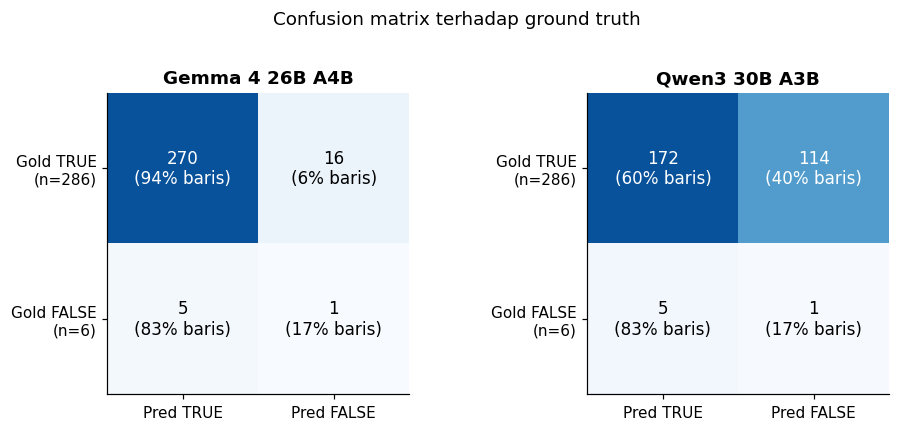

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, nama in zip(axes, ORDER):
    m = hasil[nama]
    cm = np.array([[m["TP"], m["FN"]], [m["FP"], m["TN"]]])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
    for (i, j), v in np.ndenumerate(cm):
        tot = cm[i].sum()
        ax.text(j, i, f"{v}\n({v/tot:.0%} baris)", ha="center", va="center",
                color="white" if v > cm.max() * 0.6 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["Pred TRUE", "Pred FALSE"])
    ax.set_yticks([0, 1], ["Gold TRUE\n(n=286)", "Gold FALSE\n(n=6)"])
    ax.set_title(nama, fontweight="bold")
    ax.grid(False)
fig.suptitle("Confusion matrix terhadap ground truth", y=1.02)
plt.tight_layout(); plt.show()

**Cara membaca.** Akurasi kedua model berada di bawah baseline "selalu TRUE" (97,9%), sehingga akurasi saja menyesatkan. Pada balanced accuracy, Gemma hanya sedikit di atas baseline 50%, sedangkan Qwen justru di bawahnya.

Kedua model menolak jumlah indikator gold-FALSE yang sama (1 dari 6), sehingga perbedaan performa hampir seluruhnya berasal dari kelas TRUE. Qwen jauh lebih sering menyatakan program "belum berjalan" untuk indikator yang menurut gold sudah berjalan (FN). Ini konsisten dengan profil smoke test: Qwen skeptis, Gemma cenderung percaya.

Recall FALSE dihitung dari 6 baris saja, sehingga intervalnya sangat lebar dan tidak bisa dipakai untuk membedakan kedua model.

## 4. Perbandingan berpasangan

Kedua model mengerjakan 292 indikator yang identik dengan cache pencarian yang sama, jadi keduanya bisa dibandingkan baris per baris.

In [7]:
G, Q = ORDER
bg, bq = wide[f"benar_{G}"].astype(bool), wide[f"benar_{Q}"].astype(bool)
pg, pq = wide[f"pred_{G}"].astype(bool), wide[f"pred_{Q}"].astype(bool)

pasangan = pd.DataFrame(
    [[int((bg & bq).sum()),  int((bg & ~bq).sum())],
     [int((~bg & bq).sum()), int((~bg & ~bq).sum())]],
    index=[f"{G} benar", f"{G} salah"], columns=[f"{Q} benar", f"{Q} salah"])
display(pasangan)

# Kesepakatan label antar model (Cohen's kappa), sebagai angka deskriptif
po = (pg == pq).mean()
pe = pg.mean() * pq.mean() + (1 - pg.mean()) * (1 - pq.mean())
kappa = (po - pe) / (1 - pe)
print(f"Label kedua model sama     : {int((pg == pq).sum())} / 292 ({po:.1%})")
print(f"Cohen's kappa (antar model): {kappa:.3f}")
print(f"Hanya {G} yang benar : {int((bg & ~bq).sum())} baris")
print(f"Hanya {Q} yang benar   : {int((~bg & bq).sum())} baris")
print(f"Keduanya salah          : {int((~bg & ~bq).sum())} baris")

,Qwen3 30B A3B benar,Qwen3 30B A3B salah
Gemma 4 26B A4B benar,168,103
Gemma 4 26B A4B salah,5,16


Label kedua model sama     : 184 / 292 (63.0%)
Cohen's kappa (antar model): 0.089
Hanya Gemma 4 26B A4B yang benar : 103 baris
Hanya Qwen3 30B A3B yang benar   : 5 baris
Keduanya salah          : 16 baris


In [8]:
sepakat = pg == pq
print(f"Saat sepakat  ({sepakat.sum():>3} baris): akurasi {(pg[sepakat] == wide['gold'][sepakat]).mean():.1%}")
print(f"Saat berbeda  ({(~sepakat).sum():>3} baris): {G} benar {bg[~sepakat].mean():.1%}, "
      f"{Q} benar {bq[~sepakat].mean():.1%}")

beda = wide.loc[~sepakat]
print(f"\nDari {len(beda)} baris berbeda pendapat, gold TRUE = {int(beda['gold'].sum())}, "
      f"gold FALSE = {int((~beda['gold']).sum())}")

Saat sepakat  (184 baris): akurasi 91.3%
Saat berbeda  (108 baris): Gemma 4 26B A4B benar 95.4%, Qwen3 30B A3B benar 4.6%

Dari 108 baris berbeda pendapat, gold TRUE = 108, gold FALSE = 0


**Cara membaca.** Kappa yang rendah menunjukkan kedua model sering tidak sepakat. Hampir semua ketidaksepakatan berbentuk Gemma menjawab TRUE dan Qwen menjawab FALSE, dan pada baris-baris itu gold-nya TRUE. Jadi keunggulan Gemma bukan karena Gemma lebih teliti, melainkan karena ambang keputusan Qwen jauh lebih ketat. Baris yang disepakati kedua model sangat akurat.

## 5. Kinerja per sektor

In [9]:
sek = (df.groupby(["sektor", "model_nama"])
         .agg(n=("benar", "size"), akurasi=("benar", "mean"))
         .reset_index()
         .pivot(index="sektor", columns="model_nama", values=["n", "akurasi"]))
sek = pd.DataFrame({
    "n": sek[("n", G)].astype(int),
    G: sek[("akurasi", G)],
    Q: sek[("akurasi", Q)],
})
sek["selisih (G-Q)"] = sek[G] - sek[Q]
sek = sek.sort_values(Q)
sek.style.format({G: "{:.1%}", Q: "{:.1%}", "selisih (G-Q)": "{:+.1%}"})

,n,Gemma 4 26B A4B,Qwen3 30B A3B,selisih (G-Q)
sektor,,,,
Infrastruktur,38,89.5%,39.5%,+50.0%
Energi,8,100.0%,50.0%,+50.0%
Kesehatan,36,94.4%,52.8%,+41.7%
Industri,50,84.0%,54.0%,+30.0%
Pangan,21,90.5%,57.1%,+33.3%
Sosial,61,93.4%,57.4%,+36.1%
Pertahanan,15,93.3%,60.0%,+33.3%
Pendidikan,25,100.0%,76.0%,+24.0%
Birokrasi,38,100.0%,86.8%,+13.2%


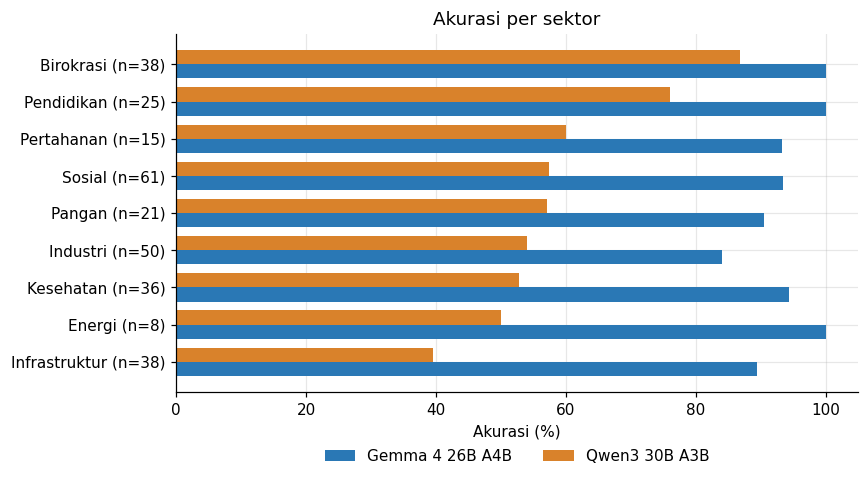

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(sek)); h = 0.38
for k, nama in enumerate(ORDER):
    ax.barh(y + (k - 0.5) * h, sek[nama] * 100, height=h, color=COLORS[nama], label=nama)
ax.set_yticks(y, [f"{s} (n={n})" for s, n in zip(sek.index, sek["n"])])
ax.set_xlabel("Akurasi (%)"); ax.set_xlim(0, 105)
ax.set_title("Akurasi per sektor")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

Karena hampir seluruh gold adalah TRUE, akurasi per sektor praktis sama dengan recall TRUE per sektor. Sektor dengan n kecil (misalnya Energi, n=8) mudah bergeser oleh satu-dua baris, jadi dibaca sebagai indikasi, bukan peringkat.

## 6. Proses pencarian (tool calling)

Bagian ini melihat bagaimana masing-masing model memakai fungsi `cari_web`. Informasi diambil dari `tool_calls_log` di JSONL. Pencarian dianggap **kosong** bila tidak mengembalikan satu pun hasil. Pencarian **ber-`site:`** adalah pencarian yang membatasi domain, baik lewat parameter `situs` maupun operator `site:` di kueri.

In [11]:
calls = []
for _, r in raw.iterrows():
    for t in r["tool_calls_log"]:
        q = t.get("query") or ""
        calls.append({
            "model_nama": r["model_nama"], "row_no": r["row_no"],
            "pakai_site": bool(t.get("situs")) or ("site:" in q.lower()),
            "n_hasil": len(t.get("hasil") or []),
        })
calls = pd.DataFrame(calls)
calls["kosong"] = calls["n_hasil"] == 0

cari = pd.DataFrame({
    nama: {
        "Total pencarian": len(c),
        "Rata-rata pencarian per indikator": len(c) / 292,
        "Rata-rata hasil per pencarian": c["n_hasil"].mean(),
        "Pencarian kosong": f"{c['kosong'].sum()} ({c['kosong'].mean():.1%})",
        "Pencarian ber-site:": f"{c['pakai_site'].sum()} ({c['pakai_site'].mean():.1%})",
        "Kosong saat ber-site:": f"{c.loc[c.pakai_site, 'kosong'].mean():.1%}",
        "Kosong saat tanpa site:": f"{c.loc[~c.pakai_site, 'kosong'].mean():.1%}",
        "Indikator dengan >=1 pencarian kosong":
            f"{int((df.loc[df.model_nama == nama, 'n_search_gagal'] > 0).sum())}",
    } for nama, c in calls.groupby("model_nama")
})[ORDER]
cari

,Gemma 4 26B A4B,Qwen3 30B A3B
Total pencarian,604,876
Rata-rata pencarian per indikator,2.068493,3.0
Rata-rata hasil per pencarian,3.756623,3.389269
Pencarian kosong,21 (3.5%),90 (10.3%)
Pencarian ber-site:,138 (22.8%),576 (65.8%)
Kosong saat ber-site:,15.2%,15.6%
Kosong saat tanpa site:,0.0%,0.0%
Indikator dengan >=1 pencarian kosong,21,67


In [12]:
# Apakah pencarian yang gagal berkaitan dengan salah jawab?
df["ada_gagal"] = df["n_search_gagal"] > 0
t = (df.groupby(["model_nama", "ada_gagal"])["benar"]
       .agg(["size", "mean"]).rename(columns={"size": "n", "mean": "akurasi"}))
t["akurasi"] = t["akurasi"].map("{:.1%}".format)
t.index = t.index.set_names(["Model", "Ada pencarian kosong?"])
t

n akurasi
Model           Ada pencarian kosong?             
Gemma 4 26B A4B False                  271   94.5%
                True                    21   71.4%
Qwen3 30B A3B   False                  225   68.4%
                True                    67   28.4%

**Cara membaca.** Semua pencarian yang kosong berasal dari pencarian ber-`site:`; pencarian tanpa pembatasan domain tidak pernah kosong. Tingkat kosong pencarian ber-`site:` hampir sama pada kedua model (sekitar 15%), tetapi Qwen memakai `site:` pada dua pertiga pencariannya, sedangkan Gemma hanya sekitar seperlima. Qwen juga selalu menghabiskan jatah 3 pencarian. Pencarian kosong ini mengindikasikan domain K/L yang ditebak dan salah (lihat Keterbatasan poin 5 di README). Indikator yang mengalami pencarian kosong juga cenderung lebih sering salah dijawab, sehingga sebagian kesalahan Qwen berakar pada retrieval, bukan penalaran.

## 7. Kualitas bukti

Nilai praktis sistem ini tidak hanya ada di label, tetapi juga di bukti yang dikutip. Kolom yang dipakai:

- `source_type`: jenis sumber menurut model.
- `evidence_year`: tahun bukti.
- `url_dari_search`: apakah URL bukti benar-benar muncul di hasil pencarian. `False` berarti URL dikarang model (halusinasi).
- `domain_goid`: apakah domain bukti berakhiran `.go.id`.

**Bukti layak** didefinisikan sebagai: URL berasal dari hasil pencarian, domain `.go.id`, tahun bukti 2025, dan jenis sumber bukan `tidak_ada`/`media`.

In [13]:
RESMI = {"lkj", "siaran_pers", "bappenas", "bps_setkab", "renstra"}
df["url_ada"] = df["source_url_pred"].fillna("").str.strip().ne("")
df["bukti_layak"] = (df["url_dari_search"] & df["domain_goid"]
                     & df["evidence_year"].astype(str).eq("2025")
                     & df["source_type"].isin(RESMI))

def ringkas_bukti(d):
    ada = d[d["url_ada"]]
    return pd.Series({
        "Baris dengan URL bukti": f"{len(ada)} / {len(d)}",
        "URL dari hasil pencarian": f"{ada['url_dari_search'].mean():.1%}",
        "URL karangan (halusinasi)": f"{int((~ada['url_dari_search']).sum())} ({(~ada['url_dari_search']).mean():.1%})",
        "  - saat pred TRUE": int((~ada.loc[ada.pred, 'url_dari_search']).sum()),
        "  - saat pred FALSE": int((~ada.loc[~ada.pred, 'url_dari_search']).sum()),
        "Domain .go.id": f"{ada['domain_goid'].mean():.1%}",
        "Bukti tahun 2025": f"{d['evidence_year'].astype(str).eq('2025').mean():.1%}",
        "Bukti layak (semua baris)": f"{d['bukti_layak'].mean():.1%}",
        "Bukti layak (pred TRUE & benar)": f"{d.loc[d.pred & d.benar, 'bukti_layak'].mean():.1%}",
    })

df.groupby("model_nama").apply(ringkas_bukti).T[ORDER]

C:\Users\Aufii\AppData\Local\Temp\ipykernel_34996\3295538459.py:21: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("model_nama").apply(ringkas_bukti).T[ORDER]


model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
Baris dengan URL bukti,291 / 292,273 / 292
URL dari hasil pencarian,96.9%,85.7%
URL karangan (halusinasi),9 (3.1%),39 (14.3%)
- saat pred TRUE,4,1
- saat pred FALSE,5,38
Domain .go.id,88.3%,86.1%
Bukti tahun 2025,98.6%,78.4%
Bukti layak (semua baris),77.7%,66.4%
Bukti layak (pred TRUE & benar),81.1%,90.1%


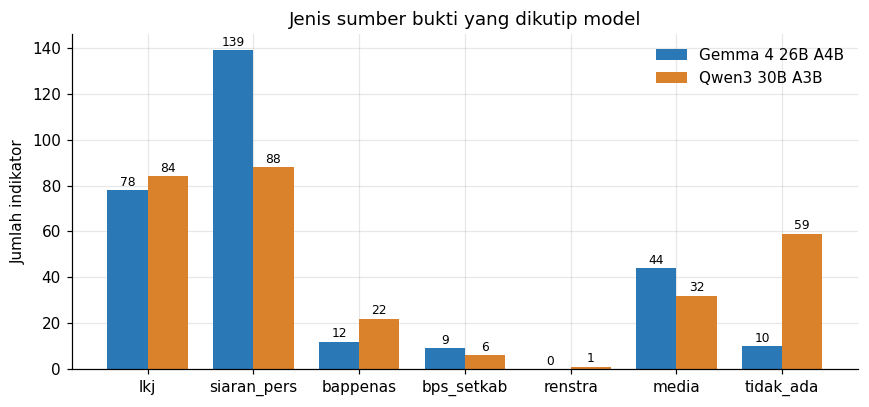

In [14]:
st_order = ["lkj", "siaran_pers", "bappenas", "bps_setkab", "renstra", "media", "tidak_ada"]
st = pd.crosstab(df["source_type"], df["model_nama"]).reindex(st_order).fillna(0).astype(int)[ORDER]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(st)); w = 0.38
for k, nama in enumerate(ORDER):
    b = ax.bar(x + (k - 0.5) * w, st[nama], width=w, color=COLORS[nama], label=nama)
    ax.bar_label(b, fontsize=8, padding=1)
ax.set_xticks(x, st.index); ax.set_ylabel("Jumlah indikator")
ax.set_title("Jenis sumber bukti yang dikutip model")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [15]:
# Akurasi per jenis sumber
acc_st = (df.groupby(["source_type", "model_nama"])["benar"].agg(["size", "mean"])
            .unstack("model_nama").reindex(st_order))
acc_st.columns = [f"{a}_{b}" for a, b in acc_st.columns]
out = pd.DataFrame({f"n {m}": acc_st[f"size_{m}"] for m in ORDER})
for m in ORDER:
    out[f"akurasi {m}"] = acc_st[f"mean_{m}"]
out.fillna(0).style.format({f"akurasi {m}": "{:.1%}" for m in ORDER} | {f"n {m}": "{:.0f}" for m in ORDER})

,n Gemma 4 26B A4B,n Qwen3 30B A3B,akurasi Gemma 4 26B A4B,akurasi Qwen3 30B A3B
source_type,,,,
lkj,78,84,94.9%,72.6%
siaran_pers,139,88,98.6%,94.3%
bappenas,12,22,83.3%,54.5%
bps_setkab,9,6,100.0%,16.7%
renstra,0,1,0.0%,0.0%
media,44,32,93.2%,46.9%
tidak_ada,10,59,0.0%,1.7%


**Cara membaca.**

- Keduanya paling banyak mengutip siaran pers dan LKj K/L. Perbedaan terbesar ada di kategori `tidak_ada`: Qwen jauh lebih sering menyatakan tidak menemukan sumber sama sekali, dan hampir semua baris ini berakhir sebagai FN.
- Secara keseluruhan Gemma lebih sering menghasilkan bukti layak. Namun **ketika Qwen menjawab TRUE dan benar, buktinya justru lebih sering layak** dibanding Gemma. Ini sejalan dengan sifat Qwen yang skeptis: ia hanya menjawab TRUE bila menemukan sumber resmi yang kuat, sedangkan Gemma juga mau menerima berita media atau sumber pemerintah daerah.
- URL karangan Qwen hampir seluruhnya muncul pada jawaban FALSE, yaitu saat model mengutip dokumen yang "seharusnya ada" tetapi tidak ditemukan. Pada jawaban TRUE, kedua model hampir tidak pernah mengarang URL.

## 8. Confidence yang dilaporkan model

Model diminta melaporkan `confidence` 0-100. Confidence yang berguna seharusnya lebih rendah pada jawaban yang salah.

In [16]:
conf = (df.groupby(["model_nama", "benar"])["confidence"]
          .agg(["size", "mean", "median", "min", "max"]).round(1))
conf.index = conf.index.set_names(["Model", "Benar?"])
display(conf)

print("Nilai confidence yang muncul:")
for nama in ORDER:
    vc = df.loc[df.model_nama == nama, "confidence"].value_counts().sort_index()
    print(f"  {nama:<16}: " + ", ".join(f"{k}->{v}" for k, v in vc.items()))

size  mean  median  min  max
Model           Benar?                              
Gemma 4 26B A4B False     21  86.9    90.0   75  100
                True     271  90.4    90.0   70  100
Qwen3 30B A3B   False    119  88.9    90.0   70   95
                True     173  89.9    90.0   85   95

Nilai confidence yang muncul:
  Gemma 4 26B A4B : 70->1, 75->1, 80->14, 85->28, 90->178, 95->68, 100->2
  Qwen3 30B A3B   : 70->4, 75->3, 80->2, 85->17, 90->251, 95->15


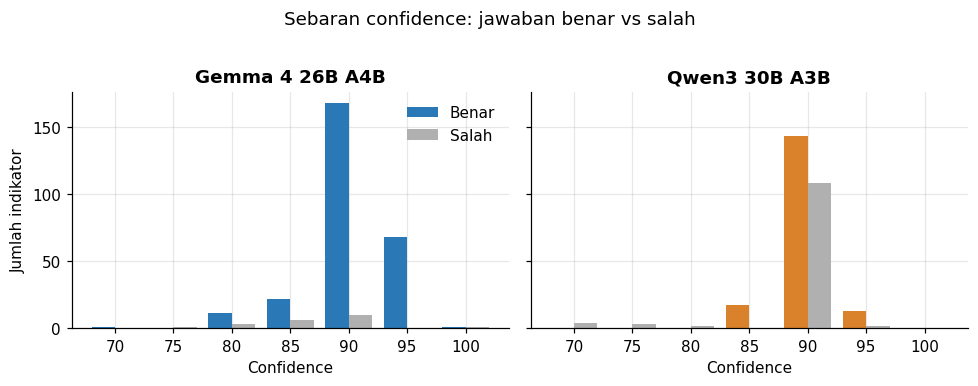

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
bins = np.arange(67.5, 105, 5)
for ax, nama in zip(axes, ORDER):
    d = df[df.model_nama == nama]
    ax.hist([d.loc[d.benar, "confidence"], d.loc[~d.benar, "confidence"]], bins=bins,
            label=["Benar", "Salah"], color=[COLORS[nama], "#b0b0b0"])
    ax.set_title(nama, fontweight="bold"); ax.set_xlabel("Confidence")
axes[0].set_ylabel("Jumlah indikator"); axes[0].legend(frameon=False)
fig.suptitle("Sebaran confidence: jawaban benar vs salah", y=1.02)
plt.tight_layout(); plt.show()

**Cara membaca.** Confidence kedua model menumpuk di sekitar 90, baik ketika jawabannya benar maupun salah. Rata-rata confidence Gemma pada jawaban salah memang sedikit lebih rendah (sekitar 87 vs 90), tetapi median keduanya sama-sama 90. Artinya confidence yang dilaporkan sendiri oleh model **tidak dapat dipakai** sebagai sinyal untuk memilah baris yang perlu diperiksa manusia. Sinyal yang lebih berguna adalah indikator proses seperti `source_type == "tidak_ada"`, `url_dari_search == False`, atau adanya pencarian kosong.

## 9. Biaya dan waktu

In [18]:
biaya = df.groupby("model_nama").agg(
    token_input_rata=("in_tok", "mean"), token_output_rata=("out_tok", "mean"),
    token_total=("in_tok", lambda s: int(s.sum() + df.loc[s.index, "out_tok"].sum())),
    latensi_median_s=("latency_s", "median"), latensi_total_menit=("latency_s", lambda s: s.sum() / 60),
    pencarian_rata=("n_search", "mean"),
).T[ORDER]
biaya.loc["token_per_jawaban_benar"] = [
    biaya.loc["token_total", m] / df.loc[df.model_nama == m, "benar"].sum() for m in ORDER]
biaya.round(1)

model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
token_input_rata,4275.5,7449.4
token_output_rata,255.6,344.6
token_total,1323086.0,2275867.0
latensi_median_s,6.4,9.7
latensi_total_menit,33.3,50.1
pencarian_rata,2.1,3.0
token_per_jawaban_benar,4882.2,13155.3


Gemma memakai sekitar 40% lebih sedikit token dan lebih cepat per indikator, sekaligus menghasilkan lebih banyak jawaban benar. Biaya per jawaban benar karena itu jauh lebih rendah pada Gemma.

## 10. Taksonomi kesalahan

Kesalahan dipisah menurut arahnya.

**False negative (gold TRUE, pred FALSE)** dikelompokkan otomatis dengan aturan berurutan di bawah (aturan pertama yang cocok dipakai):

| Kelompok | Kategori | Aturan |
| --- | --- | --- |
| Retrieval | A. Tidak ada hasil pencarian sama sekali | total hasil pencarian = 0 (termasuk bila model tidak mencari) |
| Retrieval | B. Pencarian sebagian kosong, bukti tidak ditemukan | ada pencarian kosong dan `source_type = tidak_ada` |
| Relevansi | C. Hasil ada, tetapi tidak ada yang dianggap bukti | `source_type = tidak_ada` |
| Penalaran | D. Bukti hanya dianggap dokumen perencanaan/target | ringkasan menyebut renstra/rencana/target/RKP/RPJMN |
| Penalaran | E. Bukti ditemukan tetapi dinilai belum cukup | selain di atas |

Sebagai pemeriksaan silang, untuk tiap FN dicek juga apakah **URL bukti yang dipakai model lain (yang menjawab benar) sebenarnya ikut muncul di hasil pencarian model ini**. Bila ya, model ini sudah "melihat" bukti yang sama tetapi menilainya berbeda, yang menguatkan bahwa masalahnya di penalaran.

**False positive (gold FALSE, pred TRUE)** hanya 5 baris per model, sehingga dibahas satu per satu.

Aturan ini berbasis kata kunci dan kolom diagnostik, jadi hasilnya adalah pengelompokan kasar, bukan anotasi manual.

In [19]:
POLA_RENCANA = r"renstra|perencanaan|rencana|target|\brkp\b|rpjmn|dokumen strategis"

url_terlihat = {
    (r["model_nama"], r["row_no"]): {h.get("url") for t in r["tool_calls_log"] for h in (t.get("hasil") or [])}
    for _, r in raw.iterrows()
}

def kategori_fn(r):
    if r["n_hasil"] == 0:
        return "A. Tidak ada hasil pencarian sama sekali"
    if r["source_type"] == "tidak_ada" and r["n_search_gagal"] > 0:
        return "B. Pencarian sebagian kosong, bukti tidak ditemukan"
    if r["source_type"] == "tidak_ada":
        return "C. Hasil ada, tidak ada yang dianggap bukti"
    if re.search(POLA_RENCANA, str(r["summary_pred"]).lower()):
        return "D. Bukti dianggap hanya perencanaan/target"
    return "E. Bukti ditemukan, dinilai belum cukup"

KELOMPOK = {"A": "Retrieval", "B": "Retrieval", "C": "Relevansi", "D": "Penalaran", "E": "Penalaran"}

fn = df[df.gold & ~df.pred].copy()
fn["kategori"] = fn.apply(kategori_fn, axis=1)
fn["kelompok"] = fn["kategori"].str[0].map(KELOMPOK)

# Pemeriksaan silang dengan model lain
lain = df.set_index(["model_nama", "row_no"])
def bukti_lain_terlihat(r):
    m_lain = Q if r["model_nama"] == G else G
    o = lain.loc[(m_lain, r["row_no"])]
    if not (o["pred"] and o["benar"] and o["url_dari_search"]):
        return np.nan  # model lain tidak punya bukti benar untuk dibandingkan
    return o["source_url_pred"] in url_terlihat[(r["model_nama"], r["row_no"])]
fn["bukti_model_lain_terlihat"] = fn.apply(bukti_lain_terlihat, axis=1)

tax = pd.crosstab(fn["kategori"], fn["model_nama"]).reindex(columns=ORDER, fill_value=0)
tax.loc["Total FN"] = tax.sum()
tax

model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
kategori,,
A. Tidak ada hasil pencarian sama sekali,1,0
"B. Pencarian sebagian kosong, bukti tidak ditemukan",4,30
"C. Hasil ada, tidak ada yang dianggap bukti",5,28
D. Bukti dianggap hanya perencanaan/target,6,38
"E. Bukti ditemukan, dinilai belum cukup",0,18
Total FN,16,114


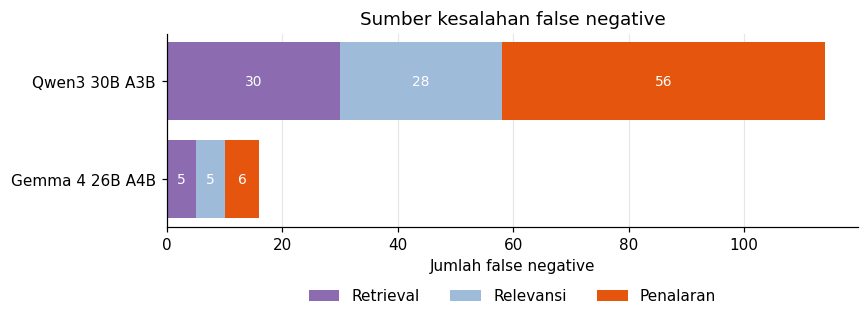

model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
kelompok,,
Retrieval,31%,26%
Relevansi,31%,25%
Penalaran,38%,49%


In [20]:
kel = pd.crosstab(fn["kelompok"], fn["model_nama"]).reindex(["Retrieval", "Relevansi", "Penalaran"]).reindex(columns=ORDER, fill_value=0)
kel_pct = kel / kel.sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
kiri = np.zeros(len(ORDER))
warna_kel = {"Retrieval": "#8c6bb1", "Relevansi": "#9ebcda", "Penalaran": "#e6550d"}
for k in kel.index:
    b = ax.barh(ORDER, kel.loc[k], left=kiri, color=warna_kel[k], label=k)
    ax.bar_label(b, labels=[f"{v}" if v else "" for v in kel.loc[k]], label_type="center", color="white", fontsize=9)
    kiri += kel.loc[k].values
ax.set_xlabel("Jumlah false negative")
ax.set_title("Sumber kesalahan false negative")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

kel_pct.style.format("{:.0%}")

In [21]:
# Pemeriksaan silang: FN yang bisa dibandingkan dengan jawaban benar model lain
x = fn.dropna(subset=["bukti_model_lain_terlihat"])
for nama in ORDER:
    s = x.loc[x.model_nama == nama, "bukti_model_lain_terlihat"].astype(bool)
    if len(s):
        print(f"{nama:<16}: {int(s.sum())} dari {len(s)} FN ({s.mean():.0%}) -> URL bukti model lain "
              f"sebenarnya muncul di hasil pencariannya sendiri")

Gemma 4 26B A4B : 0 dari 5 FN (0%) -> URL bukti model lain sebenarnya muncul di hasil pencariannya sendiri
Qwen3 30B A3B   : 31 dari 100 FN (31%) -> URL bukti model lain sebenarnya muncul di hasil pencariannya sendiri


**Cara membaca.**

- Pada Qwen, sekitar separuh FN masuk kelompok penalaran: bukti sudah ditemukan tetapi ditolak karena dianggap sekadar dokumen perencanaan/target (D) atau belum cukup (E). Sisanya terbagi hampir rata antara kegagalan retrieval (B, hampir selalu akibat `site:` yang kosong) dan hasil yang tidak dikenali sebagai bukti (C).
- Pemeriksaan silang memperkuat ini: pada sekitar sepertiga FN Qwen, URL yang dipakai Gemma untuk menjawab benar sebenarnya sudah muncul di hasil pencarian Qwen sendiri.
- Jadi masalah utama Qwen ada pada **ambang penilaian bukti yang terlalu ketat**, dengan pemakaian `site:` yang berlebihan sebagai penyumbang kedua.
- FN Gemma sedikit (16) dan tersebar. Satu kasus menarik adalah no=157 (kategori A): model tidak melakukan pencarian sama sekali karena kolom `keywords` di gold untuk indikator olahraga ini berisi "ekspor Sumatera", yang merupakan kesalahan data input, bukan kesalahan model.

### 10.1 False positive: baris gold FALSE

In [22]:
fp_rows = wide.index[~wide["gold"]]
kol = ["row_no", "sub_indikator", "model_nama", "pred", "source_type", "domain", "summary_pred"]
fp_tbl = df[df.row_no.isin(fp_rows)][kol + ["summary_gold"]].sort_values(["row_no", "model_nama"])
fp_tbl["sub_indikator"] = fp_tbl["sub_indikator"].str[:60]
fp_tbl["summary_pred"] = fp_tbl["summary_pred"].str[:220]
fp_tbl["summary_gold"] = fp_tbl["summary_gold"].str[:220]
fp_tbl.set_index(["row_no", "sub_indikator", "model_nama"])

pred  source_type                         domain  \
row_no sub_indikator                                                model_nama                                                           
11     KP 02.10.17 - Produksi vanili                                Gemma 4 26B A4B   True          lkj      ditjenbun.pertanian.go.id   
                                                                    Qwen3 30B A3B     True          lkj      ditjenbun.pertanian.go.id   
12     KP 02.10.18 - Persentase produksi komoditas pertanian organi Gemma 4 26B A4B   True          lkj  ppvtpp.setjen.pertanian.go.id   
                                                                    Qwen3 30B A3B     True        media            psp.pertanian.go.id   
44     KP 06.03.02 - Jumlah penerima manfaat Kartu Usaha Afirmatif  Gemma 4 26B A4B  False        media    www.bangda.kemendagri.go.id   
                                                                    Qwen3 30B A3B    False    tidak_ada                            NaN   
171    KP 02.12.04 - Jumlah mata air yang dipertahankan dan diselam Gemma 4 26B A4B   True          lkj            www.kehutanan.go.id   
                                                                    Qwen3 30B A3B     True        media          ksdae.kehutanan.go.id   
173    KP 02.16.01 - Luas areal preservasi yang dikembangkan        Gemma 4 26B A4B   True          lkj          ksdae.kehutanan.go.id   
                                                                    Qwen3 30B A3B     True        media              www.instagram.com   
186    KP 02.16.01 - Jumlah unit pengelola taman kehati yang difasi Gemma 4 26B A4B   True  siaran_pers                  kemenlh.go.id   
                                                                    Qwen3 30B A3B     True  siaran_pers                  kemenlh.go.id   

                                                                                                                                                                                                summary_pred  \
row_no sub_indikator                                                model_nama                                                                                                                                 
11     KP 02.10.17 - Produksi vanili                                Gemma 4 26B A4B  Program berjalan, ditandai dengan adanya Laporan Kinerja (LAKIN) Ditjen Perkebunan Tahun 2025 yang secara spesifik m...   
                                                                    Qwen3 30B A3B    Program berjalan, ditandai dengan capaian produksi vanili sebesar 1.625 ton pada tahun 2025 dalam dokumen Laporan Ki...   
12     KP 02.10.18 - Persentase produksi komoditas pertanian organi Gemma 4 26B A4B  Program berjalan, ditandai dengan adanya pelaksanaan kegiatan penyusunan Statistik Pertanian Organik Indonesia 2025 ...   
                                                                    Qwen3 30B A3B    Program berjalan, ditandai dengan penyelenggaraan Petunjuk Teknis Kegiatan Pupuk Menuju Pertanian Organik Melalui Ru...   
44     KP 06.03.02 - Jumlah penerima manfaat Kartu Usaha Afirmatif  Gemma 4 26B A4B  Program belum berjalan, ditandai dengan dokumen yang tersedia masih bersifat perencanaan, pembahasan regulasi, dan r...   
                                                                    Qwen3 30B A3B    Program belum berjalan, ditandai dengan tidak ditemukannya bukti konkret pelaksanaan kegiatan usaha afirmatif pada 2...   
171    KP 02.12.04 - Jumlah mata air yang dipertahankan dan diselam Gemma 4 26B A4B  Program berjalan, ditandai dengan adanya laporan capaian kinerja pada dokumen Laporan Kinerja Kementerian Kehutanan ...   
                                                                    Qwen3 30B A3B    Program berjalan, ditandai dengan kegiatan teknis penjagaan dan pelestarian mata air di Puncak Jawa Sungai Kolbu yan...   
173    KP 02.16.01 - Luas areal preservasi yang dikembangkan        Gemma

Kedua model salah di 5 baris gold-FALSE yang **sama persis**, dan benar di satu baris yang sama (no=44, Kartu Usaha Afirmatif, yang bukti gold-nya jelas menyatakan masih tahap perencanaan hingga 2026). Pola ini perlu diperhatikan:

- Pada **no=11** (vanili) dan **no=12** (pertanian organik), kedua model mengutip LKj/laporan tahunan resmi 2025 dari Kementan. Baris no=11 sudah tercatat `gold_suspect`.
- Pada **no=171, 173, 186**, ringkasan gold sendiri menyebut "belum ditemukan sumber" dan "perlu pencarian lanjut", sedangkan model menemukan dokumen resmi `.go.id`.

Dengan hanya 6 baris FALSE, recall FALSE sangat sensitif terhadap label gold. Angka di bagian 3 tetap memakai gold asli, tetapi baris-baris ini adalah kandidat utama bila gold diadjudikasi ulang.

### 10.2 Contoh kasus false negative

In [23]:
def contoh(nama, kategori, n=1):
    d = fn[(fn.model_nama == nama) & (fn.kategori == kategori)].head(n)
    for _, r in d.iterrows():
        print(f"[{nama}] no={r['row_no']} | {r['sektor']} | {r['kl']}")
        print(f"  Indikator : {str(r['sub_indikator'])[:100]}")
        print(f"  Kueri     : {str(r['queries_str'])[:250]}")
        print(f"  Hasil     : {r['n_hasil']} hasil, {r['n_search_gagal']} pencarian kosong, source_type={r['source_type']}")
        print(f"  Model     : {str(r['summary_pred'])[:350]}")
        print(f"  Gold      : {str(r['summary_gold'])[:250]}")
        print()

for kat in sorted(fn["kategori"].unique()):
    print("=" * 100); print(kat); print("=" * 100)
    for nama in ORDER:
        contoh(nama, kat)

A. Tidak ada hasil pencarian sama sekali
[Gemma 4 26B A4B] no=157 | Sosial | KEMENTERIAN PEMUDA DAN OLAHRAGA
  Indikator : PP 04.22 - Persentase penduduk berumur 10 tahun ke atas yang melakukan olahraga selama seminggu tera
  Kueri     : nan
  Hasil     : 0 hasil, 0 pencarian kosong, source_type=tidak_ada
  Model     : Program belum berjalan, ditandai dengan tidak ditemukannya bukti kegiatan konkret Kemenpora terkait indikator persentase penduduk berolahraga pada tahun 2025. Kata kunci pencarian yang diberikan (ekspor Sumatera) tidak relevan dengan indikator sosial/olahraga yang diminta.
  Gold      : Program berjalan ditandai dengan kampanye nasional peningkatan partisipasi olahraga penduduk (GEMAR, FORNAS, Kejuaraan Tarkam) aktif dijalankan Kemenpora dan Kemenko PMK di berbagai daerah, dengan target resmi RPJMN 2025-2029 sebesar 47,5% penduduk b

B. Pencarian sebagian kosong, bukti tidak ditemukan
[Gemma 4 26B A4B] no=81 | Sosial | KEMENTERIAN KOMUNIKASI DAN DIGITAL
  Indikator : KP 

## 11. Evaluasi isi summary

Summary model **tidak** dinilai dari kemiripan teksnya dengan `summary_gold`. Satu indikator bisa punya lebih dari satu bukti yang sah: gold mungkin disusun dari sumber A, sementara model memakai sumber B yang sama-sama valid. Kalau dinilai dari kemiripan teks, model akan dihukum justru ketika menemukan bukti alternatif yang benar.

Karena itu summary dinilai terhadap **sumbernya sendiri** dan terhadap **indikatornya**. Gold hanya menjadi salah satu acuan di rubrik manual.

| Sub-bagian | Pertanyaan | Butuh gold? | Cara |
| --- | --- | --- | --- |
| 11.1 Groundedness | Apakah angka di summary benar-benar ada di sumber yang dilihat model? | Tidak | Otomatis |
| 11.2 Relevansi | Apakah summary dan sumbernya membahas indikator yang ditanyakan? | Tidak | Otomatis |
| 11.3 Rubrik manual | Apakah buktinya valid, baik sama dengan gold maupun berbeda? | Sebagai acuan | Manual pada sampel |

Model hanya menerima judul dan cuplikan hasil pencarian (bukan isi dokumen), dan semuanya tersimpan di `tool_calls_log`. Jadi apa pun yang ditulis model seharusnya bisa dilacak ke cuplikan tersebut.

### 11.1 Groundedness angka

Setiap angka di `summary_pred` (misalnya "1.625 ton", "81,29%") dicari di tiga tempat, berurutan:

1. **Sumber yang dikutip**: judul dan cuplikan hasil pencarian dengan URL = `source_url_pred`.
2. **Hasil pencarian lain** yang diterima model pada baris yang sama.
3. **Teks indikator** yang diberikan di prompt (`sub_indikator`, `target_2025`, `satuan`), misalnya model mengulang target.

Angka yang tidak ada di ketiganya disebut **tak berdasar**: model menyebut angka yang tidak pernah ia lihat. Tahun (2019-2030) dan angka satu digit tidak dihitung karena terlalu umum. Pencocokan dilakukan atas digitnya saja, sehingga "1.625" dan "1,625" dianggap sama. Pembulatan juga diterima: "Rp8,48 triliun" dianggap cocok dengan "Rp8.482.433.079.000" di cuplikan.

`summary_gold` ikut dihitung jumlah angkanya sebagai pembanding tingkat kespesifikan, tetapi tidak dicek groundedness-nya karena sumber gold tidak ada di log.

In [24]:
RE_ANGKA = re.compile(r"\d+(?:[.,]\d+)*")

def angka_klaim(teks):
    # Ambil angka bermakna dari teks: buang tahun dan angka satu digit
    out = []
    for tok in RE_ANGKA.findall(str(teks) if pd.notna(teks) else ""):
        dig = re.sub(r"\D", "", tok).lstrip("0")
        if len(dig) < 2:
            continue
        if re.fullmatch(r"\d{4}", tok) and 2019 <= int(tok) <= 2030:
            continue
        out.append(dig)
    return out

def set_digit(teks):
    return {re.sub(r"\D", "", t).lstrip("0") for t in RE_ANGKA.findall(teks)}

def ada_di(a, himpunan):
    # Cocok persis, atau angka summary adalah pembulatan (awalan) angka yang lebih panjang,
    # misalnya "8,48 triliun" dari "8.482.433.079.000"
    return a in himpunan or (len(a) >= 3 and any(len(x) > len(a) and x.startswith(a) for x in himpunan))

log_map = {(r["model_nama"], r["row_no"]): r["tool_calls_log"] for _, r in raw.iterrows()}

def teks_sumber(nama, row_no, url):
    dikutip, lain = [], []
    for t in log_map[(nama, row_no)]:
        for h in (t.get("hasil") or []):
            s = f"{h.get('judul') or ''} {h.get('cuplikan') or ''}"
            (dikutip if url and h.get("url") == url else lain).append(s)
    return " ".join(dikutip), " ".join(lain)

rows = []
for _, r in df.iterrows():
    url = r["source_url_pred"] if pd.notna(r["source_url_pred"]) else None
    dikutip, lain = teks_sumber(r["model_nama"], r["row_no"], url)
    s_dik, s_lain = set_digit(dikutip), set_digit(lain)
    s_prompt = set_digit(f"{r['sub_indikator']} {r['target_2025']} {r['satuan']}")
    status = []
    for a in angka_klaim(r["summary_pred"]):
        if ada_di(a, s_dik):      status.append("dikutip")
        elif ada_di(a, s_lain):   status.append("hasil_lain")
        elif ada_di(a, s_prompt): status.append("prompt")
        else:               status.append("tak_berdasar")
    rows.append({"model_nama": r["model_nama"], "row_no": r["row_no"],
                 "teks_sumber_dikutip": dikutip, "status_angka": status})
gr = pd.DataFrame(rows)
df = df.drop(columns=[c for c in ["teks_sumber_dikutip", "status_angka"] if c in df]).merge(
    gr, on=["model_nama", "row_no"])

df["n_angka"] = df["status_angka"].str.len()
df["n_tak_berdasar"] = df["status_angka"].apply(lambda s: s.count("tak_berdasar"))

def label_ground(s):
    if not s:                   return "Tanpa angka"
    if "tak_berdasar" in s:     return "Ada angka tak berdasar"
    if all(x == "dikutip" for x in s): return "Semua angka dari sumber dikutip"
    return "Semua angka dari hasil pencarian/prompt"
df["groundedness"] = df["status_angka"].apply(label_ground)

URUT_G = ["Semua angka dari sumber dikutip", "Semua angka dari hasil pencarian/prompt",
          "Ada angka tak berdasar", "Tanpa angka"]
tg = pd.crosstab(df["groundedness"], df["model_nama"]).reindex(URUT_G).fillna(0).astype(int)[ORDER]
tg_pct = (tg / tg.sum()).map("{:.1%}".format)
display(tg.astype(str) + " (" + tg_pct + ")")

# Tingkat angka (bukan baris)
semua = df.explode("status_angka").dropna(subset=["status_angka"]).reset_index(drop=True)
ta = pd.crosstab(semua["status_angka"], semua["model_nama"], normalize="columns").reindex(
    ["dikutip", "hasil_lain", "prompt", "tak_berdasar"]).fillna(0)[ORDER]
print("Proporsi seluruh angka yang disebut di summary:")
display(ta.style.format("{:.1%}"))

df["n_angka_gold"] = df["summary_gold"].apply(lambda t: len(angka_klaim(t)))
spes = pd.DataFrame({
    "Summary memuat angka": df.groupby("model_nama")["n_angka"].apply(lambda s: f"{(s > 0).mean():.1%}"),
    "Rata-rata angka per summary": df.groupby("model_nama")["n_angka"].mean().round(2),
}).T[ORDER]
spes["Gold (acuan)"] = [f"{(df.drop_duplicates('row_no')['n_angka_gold'] > 0).mean():.1%}",
                        round(df.drop_duplicates("row_no")["n_angka_gold"].mean(), 2)]
spes

model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
groundedness,,
Semua angka dari sumber dikutip,55 (18.8%),79 (27.1%)
Semua angka dari hasil pencarian/prompt,35 (12.0%),46 (15.8%)
Ada angka tak berdasar,3 (1.0%),3 (1.0%)
Tanpa angka,199 (68.2%),164 (56.2%)


Proporsi seluruh angka yang disebut di summary:


model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
status_angka,,
dikutip,65.6%,64.0%
hasil_lain,30.4%,24.4%
prompt,1.6%,9.1%
tak_berdasar,2.4%,2.4%


model_nama,Gemma 4 26B A4B,Qwen3 30B A3B,Gold (acuan)
Summary memuat angka,31.8%,43.8%,86.0%
Rata-rata angka per summary,0.43,0.56,3.65


In [25]:
# Groundedness menurut label prediksi
t = (df.groupby(["model_nama", "pred"])["groundedness"].value_counts(normalize=True)
       .unstack().reindex(columns=URUT_G).fillna(0))
t.index = t.index.set_names(["Model", "Pred"])
t.style.format("{:.1%}")

In [26]:
# Contoh summary yang memuat angka tak berdasar
cth = df[df["n_tak_berdasar"] > 0]
for nama in ORDER:
    print("=" * 100); print(nama, f"- {int((cth.model_nama == nama).sum())} baris"); print("=" * 100)
    for _, r in cth[cth.model_nama == nama].head(3).iterrows():
        tak = [a for a, s in zip(angka_klaim(r["summary_pred"]), r["status_angka"]) if s == "tak_berdasar"]
        print(f"no={r['row_no']} | pred={r['pred']} | angka tak berdasar (digit): {tak}")
        print(f"  Summary : {str(r['summary_pred'])[:300]}")
        print(f"  Sumber  : {str(r['teks_sumber_dikutip'])[:300] or '(URL tidak ada di hasil pencarian)'}")
        print()

Gemma 4 26B A4B - 3 baris
no=127 | pred=True | angka tak berdasar (digit): ['514']
  Summary : Program berjalan, ditandai dengan adanya publikasi hasil analisis Food Security and Vulnerability Atlas (FSVA) tahun 2025 oleh Badan Pangan Nasional. Data menunjukkan pemetaan wilayah tahan pangan dan rentan pangan pada 514 kabupaten/kota telah dilakukan pada tahun 2025.
  Sumber  : Publikasi Pers Rabu, 27 Agustus 2025 Badan Pangan ... “Hasil analisis FSVA 2025 menunjukkan bahwa 433 kabupaten/kota (84,24%) masuk kategori wilayah tahan pangan, sementara 81 kabupaten/kota (15,76 ...

no=164 | pred=True | angka tak berdasar (digit): ['63']
  Summary : Program berjalan, ditandai dengan adanya Keputusan Menteri Pendidikan Tinggi, Sains, dan Teknologi Nomor 63/M/KEP/2025 yang menetapkan penugasan asesor untuk uji kompetensi jabatan akademik dosen. Selain itu, terdapat regulasi terkait persyaratan promosi dosen ke jenjang Lektor Kepala yang aktif pad
  Sumber  : keputusan menteri pendidikan tinggi, 

**Cara membaca.** Baris "Ada angka tak berdasar" adalah summary yang menyebut angka yang tidak ada di cuplikan mana pun yang diterima model, jadi angka itu berasal dari pengetahuan internal model atau dikarang. Summary seperti ini tetap bisa berlabel benar, tetapi isinya tidak bisa dipertanggungjawabkan dari bukti yang ada.

Temuan yang lebih menonjol justru soal **kespesifikan**: summary gold hampir selalu memuat angka capaian, sedangkan summary kedua model jauh lebih jarang. Ini wajar karena model hanya membaca cuplikan 250 karakter, sementara penyusun gold membaca dokumennya. Summary model lebih tepat dibaca sebagai "penunjuk bukti" daripada laporan capaian.

Angka yang diturunkan model sendiri (penjumlahan, konversi mata uang) juga tercatat sebagai tak berdasar, jadi contoh di atas perlu dibaca satu per satu. Cek ini hanya menangkap angka. Klaim berbentuk kalimat (nama kegiatan, lokasi) tidak ikut diperiksa, sehingga hasilnya adalah batas bawah untuk isi yang tak berdasar. Karena dicocokkan per digit, angka yang kebetulan sama dengan angka lain di cuplikan bisa lolos, jadi pengecekan ini juga cenderung longgar.

### 11.2 Relevansi terhadap indikator

Kata kunci diambil dari nama indikator (`sub_indikator`, tanpa kode KP/PP dan kata umum seperti "jumlah", "persentase"). Lalu dihitung berapa bagian kata kunci itu yang muncul di:

- **summary model**,
- **cuplikan sumber yang dikutip model**, dan
- **summary gold**, sebagai pembanding: seberapa tinggi cakupan kata kunci pada summary yang disusun manusia.

Pencocokan memakai 5 huruf pertama kata (stemming kasar), sehingga "deklarasi" cocok dengan "mendeklarasikan" maupun "dideklarasikan". Summary yang cakupannya jauh di bawah gold mengindikasikan bukti yang tidak spesifik ke indikator.

In [27]:
STOP = set('''yang dan di ke dari untuk dengan pada dalam oleh atau serta terhadap per jumlah persentase
indeks tingkat nilai rasio capaian ini itu sebagai adalah tahun program kegiatan secara telah
berdasarkan melalui antara lain bagi para tiap setiap total rata-rata baru the of and'''.split())

def kata_kunci(ind):
    ind = re.sub(r"^(KP|PP|PN)\s*[\d.]+\s*-\s*", "", str(ind))
    kata = re.findall(r"[a-zA-Z]{3,}", ind.lower())
    return sorted({k[:5] for k in kata if k not in STOP})

def cakupan(kunci, teks):
    if not kunci or not isinstance(teks, str) or not teks.strip():
        return np.nan
    t = teks.lower()
    return sum(k in t for k in kunci) / len(kunci)

df["kata_kunci"] = df["sub_indikator"].apply(kata_kunci)
df["rel_summary"] = [cakupan(k, s) for k, s in zip(df["kata_kunci"], df["summary_pred"])]
df["rel_sumber"]  = [cakupan(k, s) for k, s in zip(df["kata_kunci"], df["teks_sumber_dikutip"])]
df["rel_gold"]    = [cakupan(k, s) for k, s in zip(df["kata_kunci"], df["summary_gold"])]

rel = df.groupby(["model_nama", "pred"])[["rel_summary", "rel_sumber"]].mean()
rel.index = rel.index.set_names(["Model", "Pred"])
display(rel.style.format("{:.1%}"))

gold_ref = df.drop_duplicates("row_no")["rel_gold"].mean()
print(f"Acuan: cakupan kata kunci pada summary gold = {gold_ref:.1%}")
print(f"(cakupan sumber NaN berarti URL tidak ada di hasil pencarian, sehingga tidak dihitung)")

Acuan: cakupan kata kunci pada summary gold = 70.2%
(cakupan sumber NaN berarti URL tidak ada di hasil pencarian, sehingga tidak dihitung)


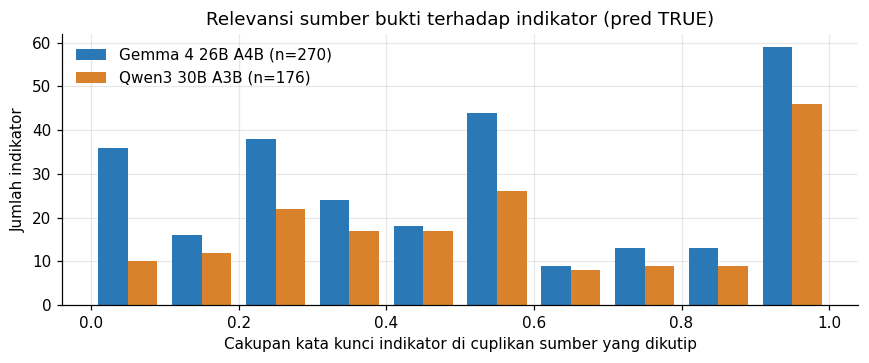

Gemma 4 26B A4B : 90 dari 270 jawaban TRUE (33.3%) bersumber cuplikan yang memuat < 1/3 kata kunci indikator
Qwen3 30B A3B   : 44 dari 176 jawaban TRUE (25.0%) bersumber cuplikan yang memuat < 1/3 kata kunci indikator


In [28]:
# Sebaran cakupan kata kunci pada sumber yang dikutip, hanya untuk jawaban TRUE
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 11)
data = [df.loc[(df.model_nama == m) & df.pred, "rel_sumber"].dropna() for m in ORDER]
label_n = [f"{m} (n={len(d)})" for m, d in zip(ORDER, data)]          # baru
ax.hist(data, bins=bins, label=label_n, color=[COLORS[m] for m in ORDER])  # label=ORDER diganti label_n
ax.set_xlabel("Cakupan kata kunci indikator di cuplikan sumber yang dikutip")
ax.set_ylabel("Jumlah indikator")
ax.set_title("Relevansi sumber bukti terhadap indikator (pred TRUE)")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("gambar_5_6_relevansi.png", dpi=200, bbox_inches="tight")  # baru, opsional
plt.show()

AMBANG = 1 / 3
low = df[df.pred & (df["rel_sumber"] < AMBANG)]
for m in ORDER:
    n_true = int((df.pred & (df.model_nama == m) & df["rel_sumber"].notna()).sum())
    n_low = int((low.model_nama == m).sum())
    print(f"{m:<16}: {n_low} dari {n_true} jawaban TRUE ({n_low/n_true:.1%}) bersumber "
          f"cuplikan yang memuat < 1/3 kata kunci indikator")

**Cara membaca.** Sumber dengan cakupan kata kunci rendah belum tentu salah, karena cuplikan hanya 250 karakter dan bisa saja dokumennya relevan. Namun jawaban TRUE yang bersandar pada cuplikan seperti ini adalah kandidat pertama untuk diperiksa manual, karena model menyimpulkan "program berjalan" dari teks yang nyaris tidak menyebut indikatornya.

### 11.3 Rubrik manual pada sampel

Validitas bukti pada akhirnya perlu dinilai manusia. Sel di bawah membuat lembar isian berisi **30 summary TRUE acak per model** (total 60), yang diacak urutannya dan **tanpa nama model** (penilaian buta). Setiap baris memuat indikator, summary gold, summary model, URL, dan cuplikan sumber yang dikutip.

Isi kolom `penilaian` dengan salah satu kode berikut:

| Kode | Arti |
| --- | --- |
| `SETARA_GOLD` | Bukti atau kesimpulannya pada dasarnya sama dengan gold |
| `BEDA_VALID` | Sumbernya berbeda dari gold, tetapi sah (resmi/kredibel, tahun 2025, relevan) dan mendukung kesimpulan |
| `TIDAK_VALID` | Sumber tidak relevan, bukan tahun 2025, tidak kredibel, atau isinya tidak mendukung klaim summary |

Kolom `catatan` opsional. Buka URL-nya bila cuplikan tidak cukup untuk menilai.

Lembar dibuat hanya sekali (tidak menimpa file yang sudah diisi). Kunci model disimpan di file terpisah dan baru dipakai saat pengolahan.

In [29]:
F_RUBRIK = DATA_OUT / "rubrik_summary_sampel.csv"
F_KUNCI  = DATA_OUT / "rubrik_summary_kunci.csv"
N_SAMPEL, SEED = 30, 42

if F_RUBRIK.exists():
    print(f"Lembar sudah ada, tidak dibuat ulang: {F_RUBRIK}")
else:
    samp = (pd.concat([d.sample(n=min(N_SAMPEL, len(d)), random_state=SEED)
                       for _, d in df[df.pred].groupby("model_nama")])
            .sample(frac=1, random_state=SEED)
            .reset_index(drop=True))
    samp["kode_sampel"] = [f"S{i+1:03d}" for i in range(len(samp))]

    lembar = pd.DataFrame({
        "kode_sampel": samp["kode_sampel"],
        "row_no": samp["row_no"],
        "sub_indikator": samp["sub_indikator"],
        "target_2025": samp["target_2025"].astype(str) + " " + samp["satuan"].astype(str),
        "summary_gold": samp["summary_gold"],
        "summary_model": samp["summary_pred"],
        "source_url_model": samp["source_url_pred"],
        "cuplikan_sumber_dikutip": samp["teks_sumber_dikutip"].replace("", "(URL tidak ada di hasil pencarian)"),
        "penilaian": "",
        "catatan": "",
    })
    lembar.to_csv(F_RUBRIK, index=False, encoding="utf-8-sig")
    samp[["kode_sampel", "model_nama", "row_no"]].to_csv(F_KUNCI, index=False, encoding="utf-8-sig")
    print(f"Lembar isian dibuat : {F_RUBRIK} ({len(lembar)} baris)")
    print(f"Kunci model         : {F_KUNCI}")

Lembar sudah ada, tidak dibuat ulang: ..\data\output\rubrik_summary_sampel.csv


In [30]:
KODE = ["SETARA_GOLD", "BEDA_VALID", "TIDAK_VALID"]

isi = pd.read_csv(F_RUBRIK, encoding="utf-8-sig", dtype=str).fillna("")
isi["penilaian"] = isi["penilaian"].str.strip().str.upper()
terisi = isi[isi["penilaian"].isin(KODE)]

if terisi.empty:
    print(f"Belum ada penilaian di {F_RUBRIK.name}. Isi kolom 'penilaian', simpan, lalu jalankan ulang sel ini.")
else:
    salah_kode = isi[(isi["penilaian"] != "") & ~isi["penilaian"].isin(KODE)]
    if len(salah_kode):
        print(f"Peringatan: {len(salah_kode)} baris berisi kode tidak dikenal: "
              f"{sorted(salah_kode['penilaian'].unique())}")
    kunci = pd.read_csv(F_KUNCI, encoding="utf-8-sig")
    hasil_rubrik = terisi.merge(kunci[["kode_sampel", "model_nama"]], on="kode_sampel")
    print(f"Terisi {len(terisi)} dari {len(isi)} baris\n")

    tr = pd.crosstab(hasil_rubrik["penilaian"], hasil_rubrik["model_nama"]).reindex(KODE).fillna(0).astype(int)
    tr = tr.reindex(columns=[m for m in ORDER if m in tr.columns])
    n = tr.sum()
    tampil_r = tr.astype(str) + " (" + (tr / n).map("{:.0%}".format) + ")"
    tampil_r.loc["Valid (SETARA + BEDA)"] = [
        fmt_ci(int(tr.loc[["SETARA_GOLD", "BEDA_VALID"], m].sum()), int(n[m])) for m in tr.columns]
    display(tampil_r)

    valid = tr.loc[["SETARA_GOLD", "BEDA_VALID"]].sum()
    for m in tr.columns:
        if valid[m]:
            print(f"{m:<16}: {tr.loc['BEDA_VALID', m] / valid[m]:.0%} dari summary valid memakai sumber "
                  f"berbeda dari gold")

Belum ada penilaian di rubrik_summary_sampel.csv. Isi kolom 'penilaian', simpan, lalu jalankan ulang sel ini.


**Cara membaca.** Proporsi `BEDA_VALID` menunjukkan seberapa sering model menemukan bukti sah yang berbeda dari gold. Bila proporsinya besar, itu sekaligus menjadi alasan empiris mengapa kemiripan teks dengan `summary_gold` tidak dipakai sebagai ukuran kualitas summary. Proporsi `TIDAK_VALID` adalah perkiraan seberapa sering jawaban TRUE model bersandar pada bukti yang tidak layak, dan dengan n=30 per model perlu dibaca bersama interval kepercayaannya.

## 12. Ringkasan temuan

In [31]:
ring = pd.DataFrame({
    nama: {
        "Akurasi": f"{hasil[nama]['Akurasi']:.1%}",
        "Balanced accuracy": f"{hasil[nama]['Balanced accuracy']:.1%}",
        "Recall TRUE": f"{hasil[nama]['Recall TRUE']:.1%} ({hasil[nama]['TP']}/286)",
        "Recall FALSE": f"{hasil[nama]['Recall FALSE']:.1%} ({hasil[nama]['TN']}/6)",
        "Macro F1": f"{hasil[nama]['Macro F1']:.3f}",
        "False negative": hasil[nama]["FN"],
        "False positive": hasil[nama]["FP"],
        "Sumber 'tidak_ada'": int((df.loc[df.model_nama == nama, 'source_type'] == 'tidak_ada').sum()),
        "URL karangan": int((df.loc[(df.model_nama == nama) & df.url_ada, 'url_dari_search'] == False).sum()),
        "Bukti layak": f"{df.loc[df.model_nama == nama, 'bukti_layak'].mean():.1%}",
        "Token rata-rata / indikator": int(df.loc[df.model_nama == nama, ['in_tok', 'out_tok']].sum(axis=1).mean()),
        "Latensi median (s)": round(df.loc[df.model_nama == nama, 'latency_s'].median(), 1),
    } for nama in ORDER
})
ring

,Gemma 4 26B A4B,Qwen3 30B A3B
Akurasi,92.8%,59.2%
Balanced accuracy,55.5%,38.4%
Recall TRUE,94.4% (270/286),60.1% (172/286)
Recall FALSE,16.7% (1/6),16.7% (1/6)
Macro F1,0.525,0.380
False negative,16,114
False positive,5,5
Sumber 'tidak_ada',10,59
URL karangan,9,39
Bukti layak,77.7%,66.4%
